In [1]:
def newton_raphson(f, df, p0, TOL=1e-6, N0=50, criterio="paso"):
    """Algoritmo 2.3. Devuelve (p, historia).
    criterio='paso' usa |p-p0| < TOL; criterio='residuo' usa |f(p)| < TOL.
    """
    historia = [p0]
    i = 1
    while i <= N0:
        d = df(p0)
        if d == 0:
            raise ZeroDivisionError(f"f'(p0) = 0 en p0 = {p0}: la tangente es horizontal")
        p = p0 - f(p0) / d
        historia.append(p)
        cumple = abs(f(p)) < TOL if criterio == "residuo" else abs(p-p0) < TOL
        if cumple:
            return p, historia
        i += 1
        p0 = p
    raise RuntimeError(f"El método fracasó después de {N0} iteraciones")

In [2]:
f = lambda x: x**3 + 4*x**2 - 10
df = lambda x: 3*x**2 + 8*x

raiz, hist = newton_raphson(f, df, p0=1.5, TOL=1e-10)
print(raiz)  # 1.3652300134140969
print(hist)  # [1.5, 1.3652300134140969]

1.3652300134140969
[1.5, 1.3733333333333333, 1.3652620148746266, 1.3652300139161466, 1.3652300134140969, 1.3652300134140969]


In [3]:
def secante(f, p0, p1, TOL=1e-6, N0=50):
    """Algoritmo 2.4. Devuelve (p, historia), con historia = [p0, p1, p2, ..., p]."""
    # Paso 1: i = 2; q0 = f(p0); q1 = f(p1); historia empieza con p0 y p1.
    i = 2
    q0 = f(p0)
    q1 = f(p1)
    historia = [p0, p1]

    # Paso 2: mientras i <= N0, haga los pasos 3 a 6.
    while i <= N0:
        # Si q1 == q0, la secante es horizontal: lance un ZeroDivisionError con un mensaje claro.
        if q1 == q0:
            raise ZeroDivisionError(f"f(p1) == f(p0) en p0 = {p0}, p1 = {p1}: la secante es horizontal")

        # Paso 3: calcule p y agréguelo a la historia.
        p = p1 - q1 * (p1 - p0) / (q1 - q0)
        historia.append(p)

        # Paso 4: si |p - p1| < TOL, devuelva (p, historia).
        if abs(p - p1) < TOL:
            return p, historia

        # Paso 5: i = i + 1.
        i = i + 1

        # Paso 6: corra los puntos (p0, q0) <- (p1, q1) y (p1, q1) <- (p, f(p)).
        #         Es la única evaluación nueva de f en la iteración.
        p0, q0, p1, q1 = p1, q1, p, f(p)

    # Paso 7: lance un RuntimeError: "El método fracasó después de N0 iteraciones".
    raise RuntimeError(f"El método fracasó después de {N0} iteraciones")

In [4]:
# 2. Contador de evaluaciones y función de prueba
llamadas = []

def f(x):
    llamadas.append(x)
    return x**3 + 4*x**2 - 10


# 3. Ejecución y salida de resultados
llamadas.clear()
p, historia = secante(f, 1.0, 2.0, TOL=1e-6)

print("Resumen (raíz, iteraciones, llamadas):", p, len(historia) - 2, len(llamadas))
print("-" * 40)

# Imprimir específicamente p2, p3, p4 y p5
for idx in range(2, 6):
    print(f"p{idx} = {historia[idx]}")

Resumen (raíz, iteraciones, llamadas): 1.3652300134142061 6 7
----------------------------------------
p2 = 1.263157894736842
p3 = 1.3388278388278387
p4 = 1.3666163947193453
p5 = 1.3652119026318565


In [5]:
def saldo_final(i, monto=20000.0, cuota=450.0, meses=60):
    """Saldo después de pagar todas las cuotas, con interés mensual i (0.01 es 1 %)."""
    saldo = monto
    for mes in range(meses):
        saldo = saldo * (1 + i) - cuota    # Interés del mes y pago de la cuota
    return saldo

# 1. Prueba sin interés
s0 = saldo_final(0)
print("saldo_final(0) =", s0)

# 2. Encontrar la tasa mensual i usando tu función secante
i_mensual, historia = secante(saldo_final, 0.005, 0.02, TOL=1e-10)
print(f"Tasa mensual i = {i_mensual:.8f} -> En porcentaje: {i_mensual * 100:.4f}%")

# 3. Tasa efectiva anual
tea = (1 + i_mensual)**12 - 1
print(f"Tasa efectiva anual = {tea:.8f} -> En porcentaje: {tea * 100:.2f}%")

saldo_final(0) = -7000.0
Tasa mensual i = 0.01042004 -> En porcentaje: 1.0420%
Tasa efectiva anual = 0.13246148 -> En porcentaje: 13.25%


Realizamos la aproximación mediante secante 

n= 1: p_2 = 0.2500000000, P(p_2) = -6.2508e+01, |p_2-p_1| = 7.5000e-01
n= 2: p_3 = 0.7737627651, P(p_3) = -8.3831e+01, |p_3-p_2| = 5.2376e-01
n= 3: p_4 = -1.2854177835, P(p_4) = 8.7964e+02, |p_4-p_3| = 2.0592e+00
n= 4: p_5 = 0.5945955204, P(p_5) = -1.0469e+02, |p_5-p_4| = 1.8800e+00
n= 5: p_6 = 0.3946411047, P(p_6) = -8.8129e+01, |p_6-p_5| = 1.9995e-01
n= 6: p_7 = -0.6693181356, P(p_7) = 1.8371e+02, |p_7-p_6| = 1.0640e+00
n= 7: p_8 = 0.0497143976, P(p_8) = -1.9961e+01, |p_8-p_7| = 7.1903e-01
n= 8: p_9 = -0.0207541508, P(p_9) = -4.4096e+00, |p_9-p_8| = 7.0469e-02
n= 9: p_10 = -0.0407353329, P(p_10) = 1.6859e-02, |p_10-p_9| = 1.9981e-02
n=10: p_11 = -0.0406592282, P(p_11) = -1.3318e-05, |p_11-p_10| = 7.6105e-05
n=11: p_12 = -0.0406592883, P(p_12) = -4.1513e-11, |p_12-p_11| = 6.0072e-08

Convergencia alcanzada en p_12 con TOL = 1e-06


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.
findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


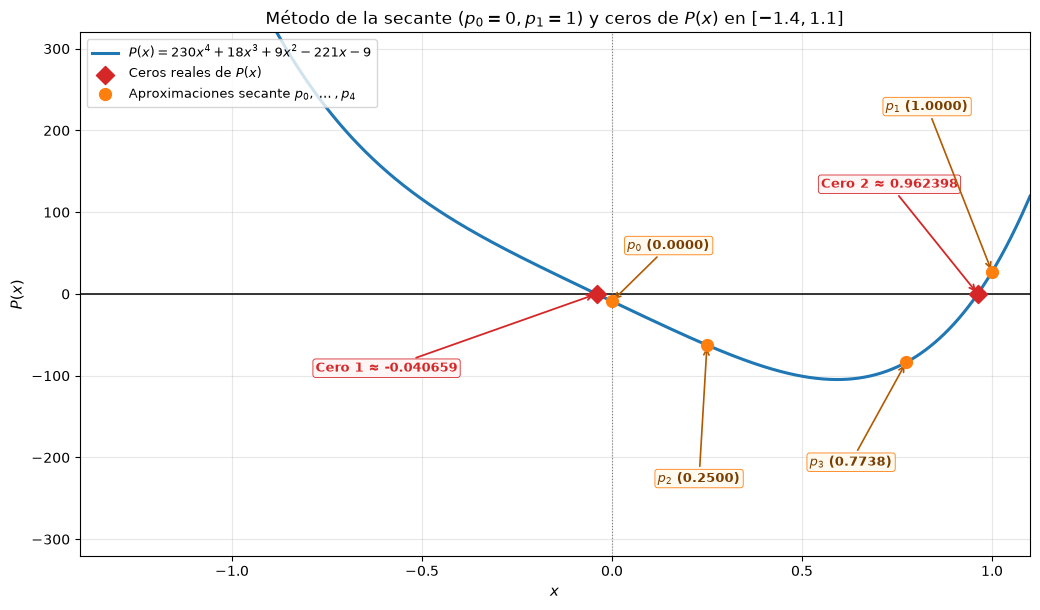

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq


def P(x):
  return 230 * x**4 + 18 * x**3 + 9 * x**2 - 221 * x - 9


# 1. Graficar primero P(x) en [-1.4, 1.1] para ubicar los ceros y elegir/evaluar puntos
x_vals = np.linspace(-1.4, 1.1, 1000)
y_vals = P(x_vals)

# Ceros reales en [-1, 0] y [0, 1] para marcarlos en la gráfica
r1 = brentq(P, -1.0, 0.0, xtol=1e-15)
r2 = brentq(P, 0.0, 1.0, xtol=1e-15)

# 2. Método de la secante desde p0 = 0, p1 = 1 con TOL = 1e-6
tol = 1e-6
p = [0.0, 1.0]
fp = [P(p[0]), P(p[1])]

for n in range(1, 25):
  p_next = p[n] - fp[n] * (p[n] - p[n - 1]) / (fp[n] - fp[n - 1])
  fp_next = P(p_next)
  err = abs(p_next - p[n])
  p.append(p_next)
  fp.append(fp_next)
  print(
      f"n={n:2d}: p_{n+1} = {p_next:.10f}, P(p_{n+1}) = {fp_next:.4e},"
      f" |p_{n+1}-p_{n}| = {err:.4e}"
  )
  if n >= 4 and err < tol:
    print(f"\nConvergencia alcanzada en p_{n+1} con TOL = {tol}")
    break

# 3. Gráfica con ceros marcados y aproximaciones p0, ..., p4 numeradas
plt.figure(figsize=(10.5, 6.2))
plt.plot(
    x_vals,
    y_vals,
    label=r"$P(x) = 230x^4 + 18x^3 + 9x^2 - 221x - 9$",
    color="#1f77b4",
    linewidth=2.2,
)
plt.axhline(0, color="black", linewidth=1.1)
plt.axvline(0, color="gray", linewidth=0.8, linestyle=":")

plt.scatter(
    [r1, r2],
    [0.0, 0.0],
    color="#d62728",
    zorder=6,
    s=85,
    marker="D",
    label="Ceros reales de $P(x)$",
)
plt.annotate(
    f"Cero 1 ≈ {r1:.6f}",
    xy=(r1, 0),
    xytext=(-0.78, -95),
    arrowprops=dict(arrowstyle="->", color="#d62728", lw=1.3),
    fontsize=9.5,
    fontweight="bold",
    color="#d62728",
    bbox=dict(
        boxstyle="round,pad=0.2",
        facecolor="#fff5f5",
        edgecolor="#d62728",
        lw=0.6,
    ),
)
plt.annotate(
    f"Cero 2 ≈ {r2:.6f}",
    xy=(r2, 0),
    xytext=(0.55, 130),
    arrowprops=dict(arrowstyle="->", color="#d62728", lw=1.3),
    fontsize=9.5,
    fontweight="bold",
    color="#d62728",
    bbox=dict(
        boxstyle="round,pad=0.2",
        facecolor="#fff5f5",
        edgecolor="#d62728",
        lw=0.6,
    ),
)

p_show = p[:5]
fp_show = [P(val) for val in p_show]
plt.plot(
    p_show,
    fp_show,
    "o",
    color="#ff7f0e",
    markersize=8.5,
    zorder=7,
    label=r"Aproximaciones secante $p_0, \dots, p_4$",
)

label_pos = {
    0: (0.04, 55),
    1: (0.72, 225),
    2: (0.12, -230),
    3: (0.52, -210),
    4: (-1.35, 195),
}
for i, (px, py) in enumerate(zip(p_show, fp_show)):
  tx, ty = label_pos[i]
  plt.annotate(
      f"$p_{i}$ ({px:.4f})",
      xy=(px, py),
      xytext=(tx, ty),
      arrowprops=dict(arrowstyle="->", color="#b35900", lw=1.2),
      fontsize=9.5,
      fontweight="semibold",
      color="#7a3d00",
      bbox=dict(
          boxstyle="round,pad=0.2",
          facecolor="#fffaf0",
          edgecolor="#ff7f0e",
          lw=0.6,
      ),
  )

plt.xlim(-1.4, 1.1)
plt.ylim(-320, 320)
plt.title(
    r"Método de la secante ($p_0=0, p_1=1$) y ceros de $P(x)$ en $[-1.4, 1.1]$",
    fontsize=12.5,
)
plt.xlabel("$x$", fontsize=11)
plt.ylabel("$P(x)$", fontsize=11)
plt.grid(True, alpha=0.3)
plt.legend(loc="upper left", fontsize=9.5)
plt.tight_layout()
plt.savefig("secante_polinomio.png", dpi=150)
plt.show()

Colocamos las gráficas lado a lado para mejor visualizacion

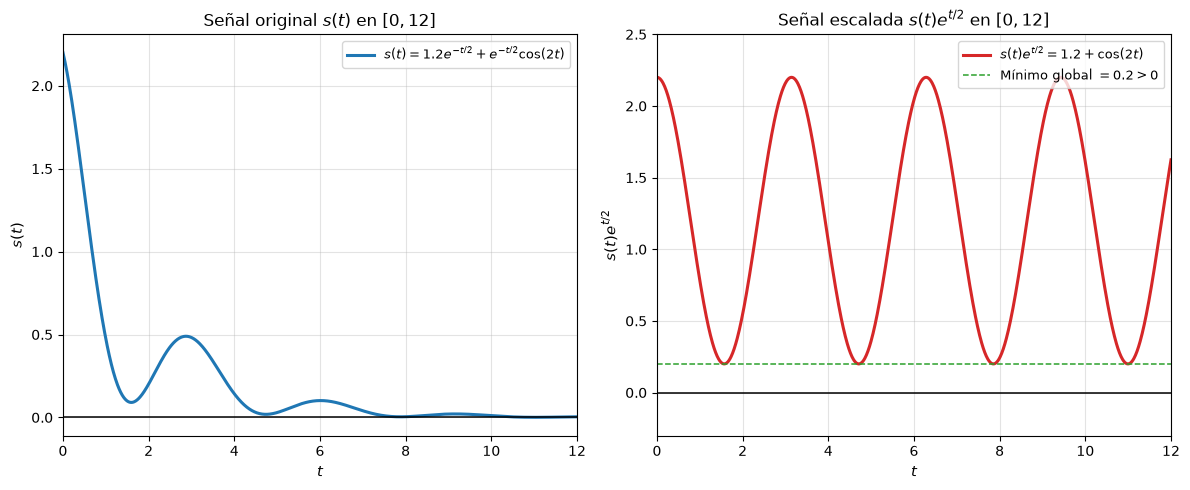

In [7]:
import matplotlib.pyplot as plt
import numpy as np


def s(t):
  return 1.2 * np.exp(-t / 2.0) + np.exp(-t / 2.0) * np.cos(2.0 * t)


def g(t):
  return s(t) * np.exp(t / 2.0)


t = np.linspace(0, 12, 1000)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Panel izquierdo: s(t)
axes[0].plot(
    t,
    s(t),
    color="#1f77b4",
    linewidth=2.2,
    label=r"$s(t) = 1.2e^{-t/2} + e^{-t/2}\cos(2t)$",
)
axes[0].axhline(0, color="black", linewidth=1.1)
axes[0].set_title(r"Señal original $s(t)$ en $[0, 12]$", fontsize=12)
axes[0].set_xlabel("$t$", fontsize=11)
axes[0].set_ylabel("$s(t)$", fontsize=11)
axes[0].set_xlim(0, 12)
axes[0].grid(True, alpha=0.35)
axes[0].legend(loc="upper right", fontsize=9.5)

# Panel derecho: s(t) * e^(t/2)
axes[1].plot(
    t,
    g(t),
    color="#d62728",
    linewidth=2.2,
    label=r"$s(t)e^{t/2} = 1.2 + \cos(2t)$",
)
axes[1].axhline(0, color="black", linewidth=1.1)
axes[1].axhline(
    0.2,
    color="#2ca02c",
    linewidth=1.1,
    linestyle="--",
    label=r"Mínimo global $= 0.2 > 0$",
)
axes[1].set_title(r"Señal escalada $s(t)e^{t/2}$ en $[0, 12]$", fontsize=12)
axes[1].set_xlabel("$t$", fontsize=11)
axes[1].set_ylabel(r"$s(t)e^{t/2}$", fontsize=11)
axes[1].set_xlim(0, 12)
axes[1].set_ylim(-0.3, 2.5)
axes[1].grid(True, alpha=0.35)
axes[1].legend(loc="upper right", fontsize=9.5)

plt.tight_layout()
plt.savefig("senales_lado_a_lado.png", dpi=150)
plt.show()

Verificamos la convergencia de los métodos 

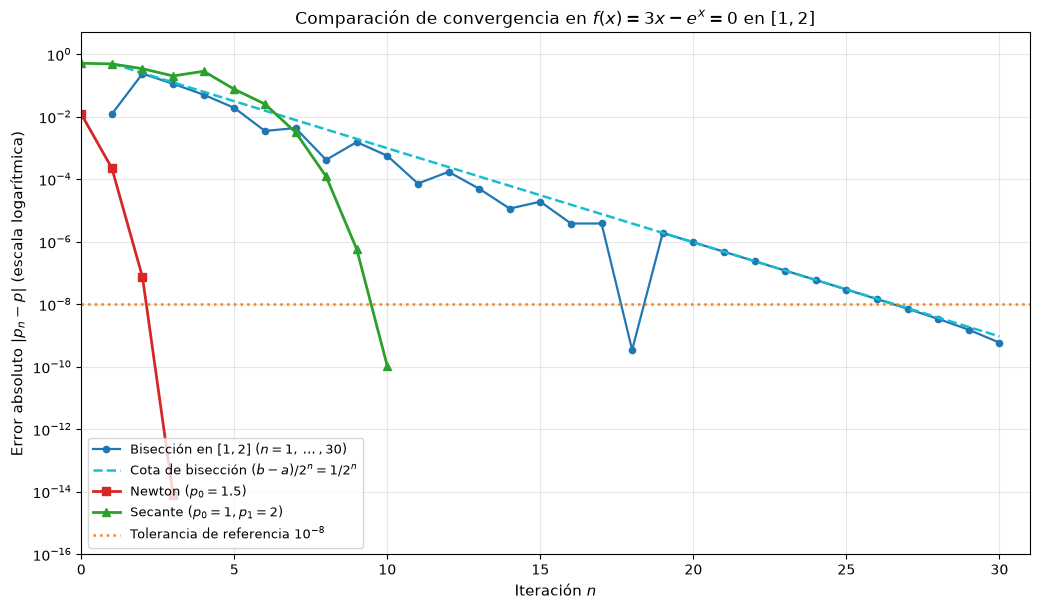

In [8]:
import matplotlib.pyplot as plt
import numpy as np


def f(x):
  return 3.0 * x - np.exp(x)


def df(x):
  return 3.0 - np.exp(x)


# 1. Raíz p con alta precisión (Secante con TOL = 1e-14)
def secante(f, p0, p1, tol=1e-14, max_iter=100):
  hist = [p0, p1]
  for _ in range(max_iter):
    f0, f1 = f(hist[-2]), f(hist[-1])
    if abs(f1 - f0) == 0:
      break
    p_next = hist[-1] - f1 * (hist[-1] - hist[-2]) / (f1 - f0)
    hist.append(p_next)
    if abs(p_next - hist[-2]) < tol:
      break
  return hist[-1], hist


p, _ = secante(f, 1.0, 2.0, tol=1e-14)


# 2. Aproximaciones de Bisección (30 iteraciones), Newton (p0=1.5) y Secante (p0=1, p1=2)
def biseccion(f, a, b, N=30):
  hist = []
  for _ in range(N):
    m = a + (b - a) / 2.0
    hist.append(m)
    if f(a) * f(m) < 0:
      b = m
    else:
      a = m
  return hist


def newton(f, df, p0, tol=1e-15, max_iter=30):
  hist = [p0]
  for _ in range(max_iter):
    fx, dfx = f(hist[-1]), df(hist[-1])
    if abs(dfx) == 0:
      break
    p_next = hist[-1] - fx / dfx
    hist.append(p_next)
    if abs(p_next - hist[-2]) < tol:
      break
  return hist


hist_bis = biseccion(f, 1.0, 2.0, N=30)
hist_new = newton(f, df, 1.5, tol=1e-15, max_iter=30)
_, hist_sec = secante(f, 1.0, 2.0, tol=1e-15, max_iter=30)


# 3. Errores (omitiendo errores == 0 para escala logarítmica)
def filtrar_positivos(indices, historia, raiz):
  errores = [abs(pn - raiz) for pn in historia]
  n_pos = [n for n, e in zip(indices, errores) if e > 0]
  e_pos = [e for e in errores if e > 0]
  return n_pos, e_pos


n_bis, err_bis = filtrar_positivos(
    range(1, len(hist_bis) + 1), hist_bis, p
)  # n = 1..30
n_new, err_new = filtrar_positivos(
    range(0, len(hist_new)), hist_new, p
)  # n = 0, 1, ...
n_sec, err_sec = filtrar_positivos(
    range(0, len(hist_sec)), hist_sec, p
)  # n = 0, 1, ...

# 4. Cota de la bisección (b - a) / 2^n y gráfica semilogy
n_cota = np.arange(1, 31)
cota_bis = (2.0 - 1.0) / (2.0**n_cota)

plt.figure(figsize=(10.5, 6.2))
plt.semilogy(
    n_bis,
    err_bis,
    "o-",
    color="#1f77b4",
    markersize=4.5,
    linewidth=1.6,
    label=r"Bisección en $[1, 2]$ ($n=1,\dots,30$)",
)
plt.semilogy(
    n_cota,
    cota_bis,
    "--",
    color="#17becf",
    linewidth=1.8,
    label=r"Cota de bisección $(b-a)/2^n = 1/2^n$",
)
plt.semilogy(
    n_new,
    err_new,
    "s-",
    color="#d62728",
    markersize=6,
    linewidth=2.0,
    label=r"Newton ($p_0 = 1.5$)",
)
plt.semilogy(
    n_sec,
    err_sec,
    "^-",
    color="#2ca02c",
    markersize=6,
    linewidth=2.0,
    label=r"Secante ($p_0 = 1, p_1 = 2$)",
)
plt.axhline(
    1e-8,
    color="#ff7f0e",
    linestyle=":",
    linewidth=1.8,
    label=r"Tolerancia de referencia $10^{-8}$",
)

plt.title(
    r"Comparación de convergencia en $f(x) = 3x - e^x = 0$ en $[1, 2]$",
    fontsize=12.5,
)
plt.xlabel(r"Iteración $n$", fontsize=11)
plt.ylabel(r"Error absoluto $|p_n - p|$ (escala logarítmica)", fontsize=11)
plt.xlim(0, 31)
plt.ylim(1e-16, 5)
plt.grid(True, which="both", alpha=0.3)
plt.legend(loc="lower left", fontsize=9.5)
plt.tight_layout()
plt.savefig("convergencia_tres_metodos.png", dpi=150)
plt.show()

## Ejercicios numéricos adicionales: ceros del polinomio y ceros de $f(x)$

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq, newton

# Polinomio P(x)
def P(x):
    return 230*x**4 + 18*x**3 + 9*x**2 - 221*x - 9

def dP(x):
    return 920*x**3 + 54*x**2 + 18*x - 221

# Arranques solicitados
raiz_sec_extremos, hist_sec_extremos = secante(P, 0.0, 1.0, 1e-10)
raiz_new_medio, hist_new_medio = newton_raphson(P, dP, 0.5, TOL=1e-10)
print("Secante desde [0,1]:", f"{raiz_sec_extremos:.10f}")
print("Newton desde 0.5:", f"{raiz_new_medio:.10f}")

# Arranque que sí encuentra el cero positivo
raiz_pos, hist_pos = secante(P, 0.5, 1.0, 1e-10)
print("Cero positivo con secante (0.5, 1.0):", f"{raiz_pos:.10f}")

## Ceros de $f(x)=\ln(x^2+1)-e^{0.4x}\cos(\pi x)$

In [ ]:
def f_log_cos(x):
    return np.log(x**2 + 1) - np.exp(0.4*x)*np.cos(np.pi*x)

def df_log_cos(x):
    return 2*x/(x**2+1) - np.exp(0.4*x)*(0.4*np.cos(np.pi*x) - np.pi*np.sin(np.pi*x))

x_plot = np.linspace(-1, 5, 3000)
y_plot = f_log_cos(x_plot)
plt.figure(figsize=(11, 5))
plt.plot(x_plot, y_plot, color="#1f77b4", linewidth=2)
plt.axhline(0, color="black", linewidth=1)
plt.axvline(0, color="gray", linewidth=.6, linestyle=":")
plt.title(r"Gráfica de $f(x)=\ln(x^2+1)-e^{0.4x}\cos(\pi x)$")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.grid(True, alpha=.3)
plt.tight_layout()
plt.savefig("ceros_log_cos.png", dpi=150)
plt.show()

# Vigésimo quinto cero positivo más pequeño
n = 25
p0 = n - 0.5
p1 = n - 0.25
raiz25, hist25 = secante(f_log_cos, p0, p1, 1e-10, 100)
print(f"Cero positivo #{n}: {raiz25:.10f}")
print(f"Residuo |f(p)|: {abs(f_log_cos(raiz25)):.3e}")

## Caso sin raíz: $e^x$ y criterio de residuo

In [ ]:
exp_fun = np.exp
dexp_fun = np.exp

# Desde p0=0, Newton da p_n=p0-n, por lo que p50=-50
print("Newton paso (p50 esperado):", -50)
try:
    exp_paso, exp_hist_paso = newton_raphson(exp_fun, dexp_fun, 0.0, TOL=1e-6, N0=50)
except RuntimeError as exc:
    print("Newton con criterio de paso:", exc)

exp_residuo, exp_hist_residuo = newton_raphson(
    exp_fun, dexp_fun, 0.0, TOL=1e-6, N0=50, criterio="residuo"
)
print("Newton con criterio de residuo:", f"{exp_residuo:.10f}")
print("Residuo:", exp_fun(exp_residuo))

raiz_scipy, info_scipy = newton(
    exp_fun, 0.0, fprime=dexp_fun, maxiter=1000, full_output=True
)
print("SciPy:", raiz_scipy, info_scipy.converged, np.exp(raiz_scipy))

## Señal sin raíces reales

In [ ]:
def s(t):
    return np.exp(-t/2)*(1.2 + np.cos(2*t))

def ds(t):
    return np.exp(-t/2)*(-0.6 - 0.5*np.cos(2*t) - 2*np.sin(2*t))

for t0 in (0.0, 2.0, 3.0, 4.0):
    pretendida, hist_t = newton_raphson(
        s, ds, t0, TOL=1e-6, N0=50, criterio="residuo"
    )
    izquierda = s(pretendida - 0.01)
    derecha = s(pretendida + 0.01)
    print(
        f"t0={t0:.1f}: t={pretendida:.10f}, s(t)={s(pretendida):.3e}, "
        f"s(t-dt)={izquierda:.3e}, s(t+dt)={derecha:.3e}"
    )

## Diagnóstico de convergencia en $3x-e^x=0$

In [ ]:
fc = lambda x: 3*x - np.exp(x)
dfc = lambda x: 3 - np.exp(x)
pref, hist_ref = secante(fc, 1.0, 2.0, 1e-14, 100)
print("Raíz de referencia:", f"{pref:.15f}")

crit_bis = [e for e in err_bis if e > 0]
crit_new = [e for e in err_new if e > 0]
crit_sec = [e for e in err_sec if e > 0]
print("Secante reduce el error en todas sus iteraciones:",
      all(a > b for a, b in zip(crit_sec, crit_sec[1:])))
print("Bisección sigue bajando:",
      all(a > b for a, b in zip(crit_bis, crit_bis[1:])))
iter_bis = next((n for n,e in zip(n_bis, err_bis) if e < 1e-8), None)
iter_sec = next((n for n,e in zip(n_sec, err_sec) if e < 1e-8), None)
print("Iteración bisección < 1e-8:", iter_bis)
print("Iteración secante < 1e-8:", iter_sec)
print("Bisección llega antes que la secante:",
      iter_bis is not None and iter_sec is not None and iter_bis < iter_sec)